# Feature Overlap Analysis: GPT Freeform Models vs RDKit

Comprehensive comparison of six GPT freeform models and the RDKit descriptor set across five dimensions:

| Part | Question |
|------|----------|
| **1** | How much do XGBoost-selected important features overlap across GPT models? |
| **2** | How much do the *complete* generated feature vocabularies overlap? |
| **3** | How much does GPT-5.2's full feature space semantically overlap with RDKit? |
| **4** | Do GPT-5.2 and RDKit select the same important features? |
| **5** | Publication figures: frequency bar, stacked unique/shared bar |

All figures saved as PNG (300 dpi) + PDF. All tables saved as CSV.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings('ignore')
import re
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize
from matplotlib.patches import Circle

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.titlesize': 11, 'axes.labelsize': 9,
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.18, 'grid.linewidth': 0.5,
    'figure.dpi': 110,
})

META_COLS = {'prestwick_ID', 'smiles_resolution', 'input', 'ProductName'}

def find_data_dir():
    here = Path().resolve()
    for c in [here / 'data', here.parent / 'data']:
        if (c / 'prestwick_library_screened.tsv.gz').exists():
            return c
    raise FileNotFoundError('Cannot find data/')

DATA_DIR     = find_data_dir()
FREEFORM_DIR = DATA_DIR / 'gpt_generation_without_guidance'
RESULTS_DIR  = DATA_DIR / 'results'
OUT_DIR      = DATA_DIR / 'feature_overlap_analysis'
TABLE_DIR    = OUT_DIR / 'tables'
OUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

MODEL_INFO = {
    'gpt-4o-mini':  {'label': 'GPT-4o-mini',  'color': '#AB47BC',
                     'file': 'gpt_features4omini_gpt-4o-mini_freeform.csv',  'results': 'freeform_gpt4omini'},
    'gpt-4.1-mini': {'label': 'GPT-4.1-mini', 'color': '#66BB6A',
                     'file': 'gpt_features_4_gpt-4.1-mini_freeform.csv',     'results': 'freeform_gpt41mini'},
    'gpt-4o':       {'label': 'GPT-4o',       'color': '#42A5F5',
                     'file': 'gpt_features4o_gpt-4o_freeform.csv',            'results': 'freeform_gpt4o'},
    'gpt-4.1':      {'label': 'GPT-4.1',      'color': '#FFA726',
                     'file': 'gpt_features_4_gpt-4.1_freeform.csv',           'results': 'freeform_gpt41'},
    'gpt-5.1':      {'label': 'GPT-5.1',      'color': '#EF5350',
                     'file': 'gpt_features5_gpt-5.1_freeform.csv',            'results': 'freeform_gpt51'},
    'gpt-5.2':      {'label': 'GPT-5.2',      'color': '#26C6DA',
                     'file': 'gpt_features5_gpt-5.2_freeform.csv',            'results': 'freeform_gpt52'},
}
RDKIT_COLOR = '#78909C'
MODEL_IDS   = list(MODEL_INFO.keys())
LABELS      = [MODEL_INFO[m]['label'] for m in MODEL_IDS]

def save_fig(fig, stem):
    for ext in ['png', 'pdf']:
        fig.savefig(OUT_DIR / f'{stem}.{ext}', dpi=300, bbox_inches='tight')
    print(f'  saved {stem}.png / .pdf')

def save_table(df, stem):
    df.to_csv(TABLE_DIR / f'{stem}.csv')
    print(f'  saved tables/{stem}.csv  ({len(df)} rows)')

def venn2_mpl(ax, n_A, n_B, n_AB, label_A, label_B, col_A='#42A5F5', col_B='#FF7043', alpha=0.45):
    r = 0.30; cx, cy = 0.50, 0.50; dx = 0.20
    for x, col in [(cx - dx, col_A), (cx + dx, col_B)]:
        p = Circle((x, cy), r, color=col, alpha=alpha, linewidth=1.2, edgecolor='#666')
        ax.add_patch(p)
    ax.text(cx - dx - 0.10, cy,        str(n_A - n_AB), ha='center', va='center', fontsize=13, fontweight='bold')
    ax.text(cx + dx + 0.10, cy,        str(n_B - n_AB), ha='center', va='center', fontsize=13, fontweight='bold')
    ax.text(cx,              cy,        str(n_AB),        ha='center', va='center', fontsize=13, fontweight='bold')
    ax.text(cx - dx - 0.10, cy - 0.38, label_A, ha='center', va='top', fontsize=9.5)
    ax.text(cx + dx + 0.10, cy - 0.38, label_B, ha='center', va='top', fontsize=9.5)
    ax.set_xlim(0.02, 0.98); ax.set_ylim(0.05, 0.95)
    ax.set_aspect('equal'); ax.axis('off')

print(f'Data : {DATA_DIR}')
print(f'Out  : {OUT_DIR}')

Data : D:\Hiwi\GPT+Mole\GPT+Mole\data
Out  : D:\Hiwi\GPT+Mole\GPT+Mole\data\feature_overlap_analysis


In [2]:
# ── Complete generated feature sets ──────────────────────────────────────────
feature_sets = {}
for mid, info in MODEL_INFO.items():
    df = pd.read_csv(FREEFORM_DIR / info['file'], nrows=1)
    feature_sets[mid] = set(c for c in df.columns if c not in META_COLS)

# ── XGBoost important features ────────────────────────────────────────────────
important_sets = {}
important_dfs  = {}
for mid, info in MODEL_INFO.items():
    p = RESULTS_DIR / info['results'] / 'top_gpt_features_mole_plus_gpt.csv'
    if p.exists():
        t = pd.read_csv(p)
        t['clean'] = t['feature_name'].str.replace('gpt__', '', regex=False)
        important_dfs[mid]  = t.sort_values('importance', ascending=False).reset_index(drop=True)
        important_sets[mid] = set(t['clean'])

# ── RDKit complete feature set (from maier chemdesc TSV) ─────────────────────
rdkit_repr    = pd.read_csv(DATA_DIR / 'maier_chemdesc_representation.tsv', sep='\t', nrows=1)
rdkit_feat_set = set(c for c in rdkit_repr.columns
                     if c not in META_COLS and c != 'prestwick_ID')

# ── RDKit important features (chemdesc XGBoost; file may be empty → use model) ─
rdkit_imp_path = RESULTS_DIR / 'rdkit_only' / 'top_gpt_features_chemdesc_only.csv'
rdkit_imp_df   = pd.read_csv(rdkit_imp_path)
if len(rdkit_imp_df) == 0:
    import joblib
    bundle  = joblib.load(RESULTS_DIR / 'rdkit_only' / 'xgb_model_chemdesc_only.pkl')
    booster = bundle['model']['booster']
    preproc = bundle['model']['preproc']
    scores  = booster.get_score(importance_type='gain')
    try:
        feat_names = list(preproc.get_feature_names_out())
    except Exception:
        feat_names = []
    rows = []
    for fid, imp in sorted(scores.items(), key=lambda x: -x[1]):
        idx   = int(fid[1:]) if fid[1:].isdigit() else -1
        fname = feat_names[idx] if 0 <= idx < len(feat_names) else fid
        clean = fname.replace('chemdesc__', '').replace('remainder__', '')
        rows.append({'feature': fid, 'importance': imp, 'feature_name': fname, 'clean': clean})
    rdkit_imp_df = pd.DataFrame(rows)
else:
    rdkit_imp_df['clean'] = rdkit_imp_df['feature_name'].str.replace('chemdesc__', '', regex=False)

rdkit_imp_set = set(rdkit_imp_df['clean'].head(20))

# ── Summary ───────────────────────────────────────────────────────────────────
print(f'{"Model":<15}  {"All features":>13}  {"Important":>10}')
print('-' * 45)
for mid in MODEL_IDS:
    print(f'{MODEL_INFO[mid]["label"]:<15}  {len(feature_sets.get(mid, set())):>13}  {len(important_sets.get(mid, set())):>10}')
print(f'{"RDKit":<15}  {len(rdkit_feat_set):>13}  {len(rdkit_imp_set):>10}')

Model             All features   Important
---------------------------------------------
GPT-4o-mini                 38          10
GPT-4.1-mini               123          10
GPT-4o                     266          10
GPT-4.1                    196          10
GPT-5.1                    509          10
GPT-5.2                    218          10
RDKit                       98          20


---
## Part 1 — Overlap of XGBoost-Selected Important Features

Each GPT model's XGBoost classifier selects the features it relies on most (by gain).
Here we compare those selected sets across all six models: how many features are shared,
how unique is each model's selection, and which features appear most consistently.

In [3]:
n = len(MODEL_IDS)

# Pairwise overlap (count + Jaccard) across IMPORTANT feature sets
imp_overlap = np.zeros((n, n), dtype=int)
imp_jaccard = np.zeros((n, n))
for i, m1 in enumerate(MODEL_IDS):
    for j, m2 in enumerate(MODEL_IDS):
        a, b  = important_sets.get(m1, set()), important_sets.get(m2, set())
        inter = len(a & b);  union = len(a | b)
        imp_overlap[i, j] = inter
        imp_jaccard[i, j] = inter / union if union else 0

# Feature frequency across all important sets
imp_counter = Counter()
for feats in important_sets.values():
    imp_counter.update(feats)

# Table 1: per-model summary
t1_rows = []
for mid in MODEL_IDS:
    imp = important_sets.get(mid, set())
    n_unique = sum(1 for f in imp
                   if all(f not in important_sets.get(m2, set()) for m2 in MODEL_IDS if m2 != mid))
    t1_rows.append({'Model': MODEL_INFO[mid]['label'],
                    'N Important': len(imp),
                    'Unique (no other model)': n_unique,
                    'Shared (>=1 other)': len(imp) - n_unique})
table1 = pd.DataFrame(t1_rows)

# Table 2: pairwise overlap matrix
table2 = pd.DataFrame(imp_overlap, index=LABELS, columns=LABELS)

# Table 4: features common to >= 2 models (ranked)
ranked_imp_rows = []
for feat, cnt in imp_counter.most_common():
    avg_imp = np.mean([important_dfs[m].set_index('clean')['importance'].get(feat, 0)
                       for m in MODEL_IDS if m in important_dfs and feat in important_dfs[m]['clean'].values])
    models_with = [MODEL_INFO[m]['label'] for m in MODEL_IDS if feat in important_sets.get(m, set())]
    ranked_imp_rows.append({'Feature': feat, 'N Models': cnt,
                            'Models': ', '.join(models_with), 'Avg Importance': round(avg_imp, 2)})
ranked_imp_df = pd.DataFrame(ranked_imp_rows)

all_common_imp = set.intersection(*[important_sets.get(m, set()) for m in MODEL_IDS]) if important_sets else set()

print('=== Part 1: Important Feature Overlap ===')
print(table1.to_string(index=False))
print()
print(f'Features in ALL {n} models: {len(all_common_imp)}  →  {sorted(all_common_imp) if all_common_imp else "none"}')
print()
print('Top 10 most frequent important features:')
for feat, cnt in imp_counter.most_common(10):
    print(f'  {feat:<48s}  {cnt}/{n} models')

=== Part 1: Important Feature Overlap ===
       Model  N Important  Unique (no other model)  Shared (>=1 other)
 GPT-4o-mini           10                        9                   1
GPT-4.1-mini           10                        6                   4
      GPT-4o           10                        8                   2
     GPT-4.1           10                        8                   2
     GPT-5.1           10                        9                   1
     GPT-5.2           10                        9                   1

Features in ALL 6 models: 0  →  none

Top 10 most frequent important features:
  molecular_weight                                  4/6 models
  heteroatom_count                                  3/6 models
  num_sulfonamide_groups                            2/6 models
  logp                                              2/6 models
  num_rotatable_bonds                               1/6 models
  polar_surface_area                                1/6 models
  l

  saved fig1_important_feature_overlap.png / .pdf


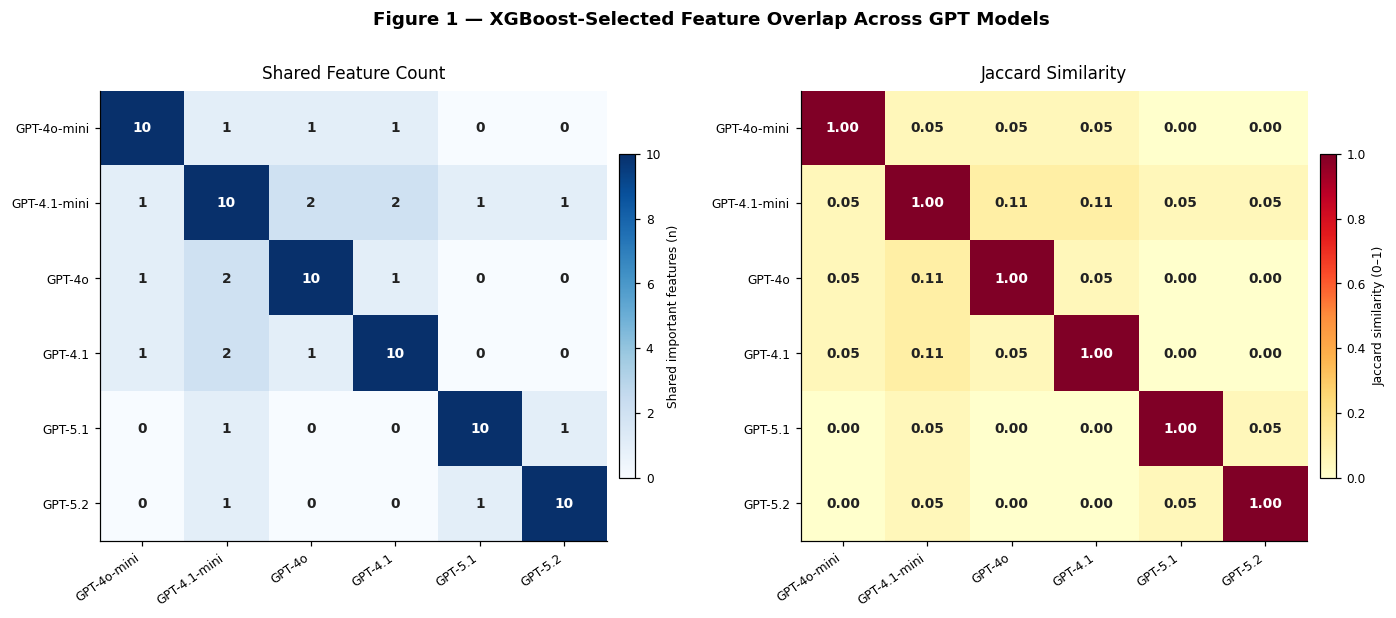

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, mat, cmap, fmt, title, cbar_label in [
    (axes[0], imp_overlap, 'Blues',  'd',    'Shared Feature Count',     'Shared important features (n)'),
    (axes[1], imp_jaccard, 'YlOrRd', '.2f',  'Jaccard Similarity',        'Jaccard similarity (0–1)'),
]:
    vmax = mat.max() if cmap == 'Blues' else 1
    im   = ax.imshow(mat, cmap=cmap, vmin=0, vmax=vmax, aspect='auto')
    ax.set_xticks(range(n)); ax.set_xticklabels(LABELS, rotation=35, ha='right', fontsize=8)
    ax.set_yticks(range(n)); ax.set_yticklabels(LABELS, fontsize=8)
    for i in range(n):
        for j in range(n):
            val = mat[i, j]
            col = 'white' if val > vmax * 0.62 else '#222'
            ax.text(j, i, format(val, fmt), ha='center', va='center', fontsize=9, color=col, fontweight='bold')
    cb = plt.colorbar(im, ax=ax, shrink=0.72, pad=0.02)
    cb.set_label(cbar_label, fontsize=8)
    ax.set_title(title, fontsize=11, pad=8)
    ax.grid(False)

fig.suptitle('Figure 1 — XGBoost-Selected Feature Overlap Across GPT Models',
             fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig(fig, 'fig1_important_feature_overlap')
plt.show()

In [5]:
print('── Table 1: Summary of Important Features ──')
print(table1.to_string(index=False))
save_table(table1, 'table1_important_feature_summary')

print()
print('── Table 2: Pairwise Overlap Matrix (important features) ──')
print(table2.to_string())
save_table(table2, 'table2_pairwise_overlap_important')

print()
print('── Table 4: Features Ranked by Frequency Across GPT Models ──')
print(ranked_imp_df[ranked_imp_df['N Models'] >= 2].to_string(index=False))
save_table(ranked_imp_df, 'table4_important_features_ranked')

── Table 1: Summary of Important Features ──
       Model  N Important  Unique (no other model)  Shared (>=1 other)
 GPT-4o-mini           10                        9                   1
GPT-4.1-mini           10                        6                   4
      GPT-4o           10                        8                   2
     GPT-4.1           10                        8                   2
     GPT-5.1           10                        9                   1
     GPT-5.2           10                        9                   1
  saved tables/table1_important_feature_summary.csv  (6 rows)

── Table 2: Pairwise Overlap Matrix (important features) ──
              GPT-4o-mini  GPT-4.1-mini  GPT-4o  GPT-4.1  GPT-5.1  GPT-5.2
GPT-4o-mini            10             1       1        1        0        0
GPT-4.1-mini            1            10       2        2        1        1
GPT-4o                  1             2      10        1        0        0
GPT-4.1                 1          

---
## Part 2 — Overlap of Complete Generated Feature Vocabularies

Each GPT model generates its own set of feature *names* autonomously. Even if two models
measure similar chemistry, they may use completely different names. This section compares
the complete generated vocabulary — every feature the model ever produced — across all six models.

In [6]:
# Pairwise overlap for COMPLETE feature sets
full_overlap = np.zeros((n, n), dtype=int)
full_jaccard = np.zeros((n, n))
for i, m1 in enumerate(MODEL_IDS):
    for j, m2 in enumerate(MODEL_IDS):
        a, b  = feature_sets.get(m1, set()), feature_sets.get(m2, set())
        inter = len(a & b);  union = len(a | b)
        full_overlap[i, j] = inter
        full_jaccard[i, j] = inter / union if union else 0

all_common_full = set.intersection(*[feature_sets.get(m, set()) for m in MODEL_IDS]) if feature_sets else set()

full_counter = Counter()
for feats in feature_sets.values():
    full_counter.update(feats)

# Summary table (generated feature counts)
t1g_rows = []
for mid in MODEL_IDS:
    feats    = feature_sets.get(mid, set())
    n_unique = sum(1 for f in feats
                   if all(f not in feature_sets.get(m2, set()) for m2 in MODEL_IDS if m2 != mid))
    t1g_rows.append({'Model': MODEL_INFO[mid]['label'],
                     'Total Generated': len(feats),
                     'Model-Specific': n_unique,
                     'Shared (>=1 other)': len(feats) - n_unique})
table1g = pd.DataFrame(t1g_rows)
table3  = pd.DataFrame(full_overlap, index=LABELS, columns=LABELS)

print('=== Part 2: Complete Feature Set Overlap ===')
print(table1g.to_string(index=False))
print()
print(f'Features common to ALL {n} models: {len(all_common_full)}')
print('First 10 common:', sorted(all_common_full)[:10])
print()
print('Top 10 most frequent generated feature names:')
for feat, cnt in full_counter.most_common(10):
    print(f'  {feat:<50s}  {cnt}/{n} models')

=== Part 2: Complete Feature Set Overlap ===
       Model  Total Generated  Model-Specific  Shared (>=1 other)
 GPT-4o-mini               38              24                  14
GPT-4.1-mini              123              77                  46
      GPT-4o              266             245                  21
     GPT-4.1              196             144                  52
     GPT-5.1              509             481                  28
     GPT-5.2              218             200                  18

Features common to ALL 6 models: 1
First 10 common: ['molecular_weight']

Top 10 most frequent generated feature names:
  molecular_weight                                    6/6 models
  topological_polar_surface_area                      5/6 models
  num_rotatable_bonds                                 4/6 models
  molar_refractivity                                  3/6 models
  num_heteroatoms                                     3/6 models
  num_aromatic_rings                           

  saved fig2_generated_feature_overlap.png / .pdf


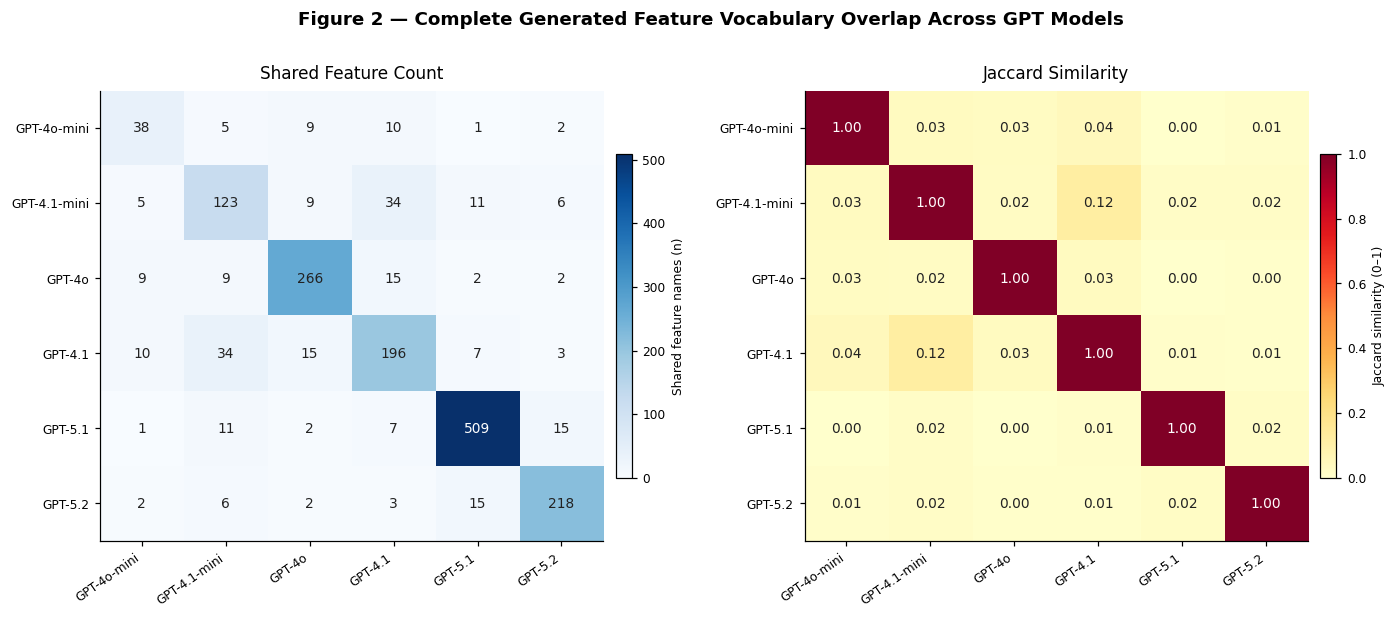

  saved tables/table1b_generated_feature_summary.csv  (6 rows)
  saved tables/table3_pairwise_overlap_generated.csv  (6 rows)


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, mat, cmap, fmt, title, cbar_label in [
    (axes[0], full_overlap, 'Blues',  'd',    'Shared Feature Count',   'Shared feature names (n)'),
    (axes[1], full_jaccard, 'YlOrRd', '.2f',  'Jaccard Similarity',      'Jaccard similarity (0–1)'),
]:
    vmax = mat.max() if cmap == 'Blues' else 1
    im   = ax.imshow(mat, cmap=cmap, vmin=0, vmax=vmax, aspect='auto')
    ax.set_xticks(range(n)); ax.set_xticklabels(LABELS, rotation=35, ha='right', fontsize=8)
    ax.set_yticks(range(n)); ax.set_yticklabels(LABELS, fontsize=8)
    for i in range(n):
        for j in range(n):
            val = mat[i, j]
            col = 'white' if val > vmax * 0.62 else '#222'
            ax.text(j, i, format(val, fmt), ha='center', va='center', fontsize=9, color=col)
    cb = plt.colorbar(im, ax=ax, shrink=0.72, pad=0.02)
    cb.set_label(cbar_label, fontsize=8)
    ax.set_title(title, fontsize=11, pad=8)
    ax.grid(False)

fig.suptitle('Figure 2 — Complete Generated Feature Vocabulary Overlap Across GPT Models',
             fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig(fig, 'fig2_generated_feature_overlap')
plt.show()

save_table(table1g, 'table1b_generated_feature_summary')
save_table(table3,  'table3_pairwise_overlap_generated')

---
## Part 3 — GPT-5.2 vs RDKit: Semantic Feature Matching

Feature names differ even when measuring the same property (e.g. `logp` vs `MolLogP`).
Exact string matching finds almost no overlap. Instead we:
1. **Normalize** names (lowercase, strip prefixes, remove punctuation)
2. Apply a **synonym dictionary** of known chemical descriptor equivalents
3. Count features that map to the same canonical form as "semantically matched"

In [8]:
def normalize(name):
    s = str(name).lower()
    for prefix in ('gpt__', 'chemdesc__', 'rdkit__', 'mole__'):
        s = s.replace(prefix, '')
    return re.sub(r'[^a-z0-9]', '', s)

SYNONYM_MAP = {
    # molecular weight
    'molecularweight': 'molwt', 'molweight': 'molwt', 'mw': 'molwt',
    # logP
    'logp': 'mollogp', 'clogp': 'mollogp', 'xlogp3': 'mollogp', 'logpest': 'mollogp', 'logpxlogp3est': 'mollogp',
    # TPSA
    'tpsa': 'tpsa', 'topologicalpolarsurfacearea': 'tpsa', 'polarsurfacearea': 'tpsa',
    # H-bond donors
    'numhbonddonors': 'numhdonors', 'hbonddonorcount': 'numhdonors',
    'hbdonorcount': 'numhdonors', 'hydrogenbonddonors': 'numhdonors',
    # H-bond acceptors
    'numhbondacceptors': 'numhacceptors', 'hbondacceptorcount': 'numhacceptors',
    'hbacceptorcount': 'numhacceptors', 'hydrogenbondacceptors': 'numhacceptors',
    # rotatable bonds
    'rotatablbonds': 'numrotatablebonds', 'rotatablbondcount': 'numrotatablebonds',
    'rotatablebondcount': 'numrotatablebonds', 'numrotatablebonds': 'numrotatablebonds',
    # aromatic rings
    'aromaticrings': 'numaromaticrings', 'aromaticringscount': 'numaromaticrings',
    'aromaticringsest': 'numaromaticrings', 'aromaticringcount': 'numaromaticrings',
    'aromaticringcount6membered': 'numaromaticrings',
    # aliphatic rings
    'aliphaticrings': 'numaliphaticrings', 'numaliphaticrings': 'numaliphaticrings',
    'aliphaticringscount': 'numaliphaticrings',
    # heavy atoms
    'heavyatomcount': 'heavyatomcount', 'numheavyatoms': 'heavyatomcount', 'heavyatoms': 'heavyatomcount',
    # molar refractivity
    'molarrefractivity': 'molmr', 'refractivity': 'molmr',
    # rings
    'ringcount': 'ringcount', 'numrings': 'ringcount', 'totalrings': 'ringcount',
    # heteroatoms
    'numheteroatoms': 'numheteroatoms', 'heteroatomcount': 'numheteroatoms',
    # fraction Csp3
    'fractioncsp3': 'fractioncsp3', 'fsp3': 'fractioncsp3',
    # valence electrons
    'numvalenceelectrons': 'numvalenceelectrons', 'valenceelectrons': 'numvalenceelectrons',
    # molar mass
    'exactmassest': 'exactmolwt', 'exactmass': 'exactmolwt',
}

def canonical(name):
    norm = normalize(name)
    return SYNONYM_MAP.get(norm, norm)

gpt52_features = feature_sets.get('gpt-5.2', set())
gpt52_can = {f: canonical(f) for f in gpt52_features}
rdkit_can  = {f: canonical(f) for f in rdkit_feat_set}

canon_to_gpt52 = {}
for f, c in gpt52_can.items():
    canon_to_gpt52.setdefault(c, []).append(f)

canon_to_rdkit = {}
for f, c in rdkit_can.items():
    canon_to_rdkit.setdefault(c, []).append(f)

matched_can = set(gpt52_can.values()) & set(rdkit_can.values())
matched_pairs = []
for c in sorted(matched_can):
    for g in canon_to_gpt52.get(c, []):
        for r in canon_to_rdkit.get(c, []):
            matched_pairs.append({'GPT-5.2 Feature': g, 'RDKit Feature': r, 'Canonical': c})

matched_gpt52  = {p['GPT-5.2 Feature'] for p in matched_pairs}
matched_rdkit  = {p['RDKit Feature']   for p in matched_pairs}
unmatched_gpt52 = sorted(gpt52_features - matched_gpt52)
unmatched_rdkit = sorted(rdkit_feat_set - matched_rdkit)
n_matched        = len(matched_pairs)

print(f'GPT-5.2 total features : {len(gpt52_features)}')
print(f'RDKit total features   : {len(rdkit_feat_set)}')
print(f'Semantically matched   : {n_matched}')
print(f'GPT-5.2 unique         : {len(unmatched_gpt52)}')
print(f'RDKit unique           : {len(unmatched_rdkit)}')
print()
print('Matched pairs:')
for p in matched_pairs:
    print(f'  {p["GPT-5.2 Feature"]:<45s} <-> {p["RDKit Feature"]}')

GPT-5.2 total features : 218
RDKit total features   : 98
Semantically matched   : 9
GPT-5.2 unique         : 209
RDKit unique           : 89

Matched pairs:
  fraction_csp3                                 <-> FractionCSP3
  logp_xlogp3_est                               <-> MolLogP
  molecular_weight                              <-> MolWt
  aromatic_ring_count_6_membered                <-> NumAromaticRings
  hbond_acceptor_count                          <-> NumHAcceptors
  hbond_donor_count                             <-> NumHDonors
  heteroatom_count                              <-> NumHeteroatoms
  rotatable_bond_count                          <-> NumRotatableBonds
  topological_polar_surface_area                <-> TPSA


  saved fig3_venn_gpt52_rdkit_full.png / .pdf


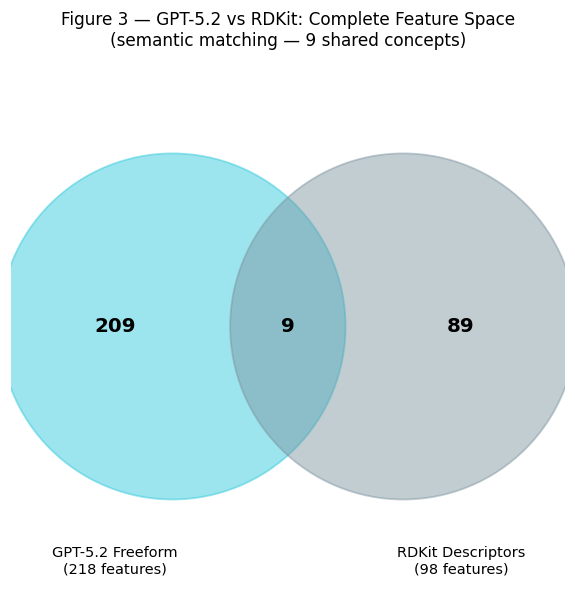

In [9]:
fig, ax = plt.subplots(figsize=(7, 5.5))
venn2_mpl(ax,
    n_A=len(gpt52_features), n_B=len(rdkit_feat_set), n_AB=n_matched,
    label_A=f'GPT-5.2 Freeform\n({len(gpt52_features)} features)',
    label_B=f'RDKit Descriptors\n({len(rdkit_feat_set)} features)',
    col_A='#26C6DA', col_B=RDKIT_COLOR)
ax.set_title(
    f'Figure 3 — GPT-5.2 vs RDKit: Complete Feature Space\n'
    f'(semantic matching — {n_matched} shared concepts)',
    fontsize=11, pad=14)
plt.tight_layout()
save_fig(fig, 'fig3_venn_gpt52_rdkit_full')
plt.show()

In [10]:
table5 = pd.DataFrame(matched_pairs)[['GPT-5.2 Feature', 'RDKit Feature', 'Canonical']]
print('── Table 5: Semantic Mapping GPT-5.2 <-> RDKit ──')
print(table5.to_string(index=False))
save_table(table5, 'table5_semantic_mapping_gpt52_rdkit')
save_table(pd.DataFrame({'GPT-5.2 Unique': unmatched_gpt52}), 'table5b_gpt52_unique')
save_table(pd.DataFrame({'RDKit Unique': unmatched_rdkit}),    'table5c_rdkit_unique')
print(f'\nFirst 15 GPT-5.2 unique: {unmatched_gpt52[:15]}')
print(f'First 15 RDKit unique  : {unmatched_rdkit[:15]}')

── Table 5: Semantic Mapping GPT-5.2 <-> RDKit ──
               GPT-5.2 Feature     RDKit Feature         Canonical
                 fraction_csp3      FractionCSP3      fractioncsp3
               logp_xlogp3_est           MolLogP           mollogp
              molecular_weight             MolWt             molwt
aromatic_ring_count_6_membered  NumAromaticRings  numaromaticrings
          hbond_acceptor_count     NumHAcceptors     numhacceptors
             hbond_donor_count        NumHDonors        numhdonors
              heteroatom_count    NumHeteroatoms    numheteroatoms
          rotatable_bond_count NumRotatableBonds numrotatablebonds
topological_polar_surface_area              TPSA              tpsa
  saved tables/table5_semantic_mapping_gpt52_rdkit.csv  (9 rows)
  saved tables/table5b_gpt52_unique.csv  (209 rows)
  saved tables/table5c_rdkit_unique.csv  (89 rows)

First 15 GPT-5.2 unique: ['acidic_site_count', 'aggregator_likelihood_est', 'amino_imino_tautomer_possible', 'a

---
## Part 4 — Important Feature Comparison: GPT-5.2 vs RDKit

Do XGBoost models trained on GPT-5.2 features and RDKit descriptors separately
pick up the same important features? We apply the same semantic matching to the
*top selected* features of each model.

In [11]:
gpt52_imp    = important_sets.get('gpt-5.2', set())
gpt52_imp_df = important_dfs.get('gpt-5.2', pd.DataFrame())

gpt52_imp_can  = {f: canonical(f) for f in gpt52_imp}
rdkit_imp_can  = {f: canonical(f) for f in rdkit_imp_set}
matched_imp_can = set(gpt52_imp_can.values()) & set(rdkit_imp_can.values())

matched_imp_pairs = []
for c in sorted(matched_imp_can):
    g_list = [f for f, cv in gpt52_imp_can.items() if cv == c]
    r_list = [f for f, cv in rdkit_imp_can.items() if cv == c]
    for g in g_list:
        for r in r_list:
            gi = gpt52_imp_df.set_index('clean')['importance'].get(g, 0) if not gpt52_imp_df.empty else 0
            ri = rdkit_imp_df.set_index('clean')['importance'].get(r, 0) if not rdkit_imp_df.empty else 0
            matched_imp_pairs.append({'GPT-5.2 Feature': g, 'GPT Importance': round(gi, 2),
                                      'RDKit Feature': r,   'RDKit Importance': round(ri, 2),
                                      'Canonical': c})

n_shared_imp = len(matched_imp_pairs)
gpt52_only_imp  = gpt52_imp  - {p['GPT-5.2 Feature'] for p in matched_imp_pairs}
rdkit_only_imp  = rdkit_imp_set - {p['RDKit Feature']   for p in matched_imp_pairs}

print(f'GPT-5.2 important : {len(gpt52_imp)}')
print(f'RDKit important   : {len(rdkit_imp_set)}')
print(f'Shared (semantic) : {n_shared_imp}')
print(f'GPT-5.2 only      : {len(gpt52_only_imp)}')
print(f'RDKit only        : {len(rdkit_only_imp)}')
if matched_imp_pairs:
    print('\nShared important features:')
    for p in matched_imp_pairs:
        print(f'  {p["GPT-5.2 Feature"]:<38s} GPTimp={p["GPT Importance"]:>8.1f}  |  {p["RDKit Feature"]:<25s} RDKitimp={p["RDKit Importance"]:>8.1f}')

GPT-5.2 important : 10
RDKit important   : 20
Shared (semantic) : 0
GPT-5.2 only      : 10
RDKit only        : 20


  saved fig4_venn_gpt52_rdkit_important.png / .pdf


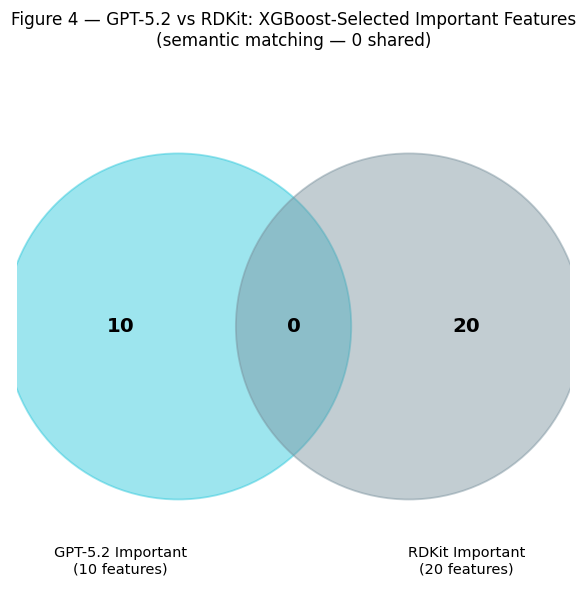

In [12]:
fig, ax = plt.subplots(figsize=(7, 5.5))
venn2_mpl(ax,
    n_A=len(gpt52_imp), n_B=len(rdkit_imp_set), n_AB=n_shared_imp,
    label_A=f'GPT-5.2 Important\n({len(gpt52_imp)} features)',
    label_B=f'RDKit Important\n({len(rdkit_imp_set)} features)',
    col_A='#26C6DA', col_B=RDKIT_COLOR)
ax.set_title(
    f'Figure 4 — GPT-5.2 vs RDKit: XGBoost-Selected Important Features\n'
    f'(semantic matching — {n_shared_imp} shared)',
    fontsize=11, pad=14)
plt.tight_layout()
save_fig(fig, 'fig4_venn_gpt52_rdkit_important')
plt.show()

In [13]:
if matched_imp_pairs:
    table6 = (pd.DataFrame(matched_imp_pairs)
              [['GPT-5.2 Feature', 'GPT Importance', 'RDKit Feature', 'RDKit Importance']]
              .sort_values('GPT Importance', ascending=False))
else:
    table6 = pd.DataFrame({'Note': ['No semantically matched important features found.']})

print('── Table 6: Shared Important Descriptors (GPT-5.2 & RDKit) ──')
print(table6.to_string(index=False))
save_table(table6, 'table6_shared_important_gpt52_rdkit')

── Table 6: Shared Important Descriptors (GPT-5.2 & RDKit) ──
                                             Note
No semantically matched important features found.
  saved tables/table6_shared_important_gpt52_rdkit.csv  (1 rows)


---
## Part 5 — Publication Figures

**Figure 5**: Frequency of the top 15 most common important features across GPT models.
**Figure 6**: Stacked bar showing unique vs shared important features per model.

  saved fig5_top15_important_freq.png / .pdf


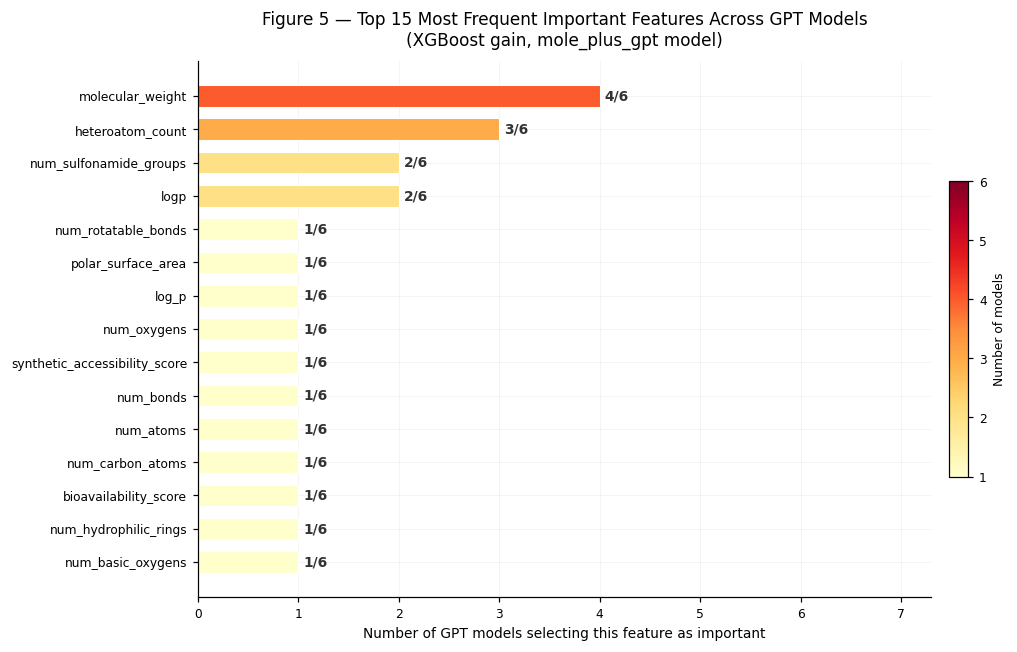

In [14]:
top15       = imp_counter.most_common(15)
names_15    = [f for f, _ in top15][::-1]
cnts_15     = [c for _, c in top15][::-1]
norm_c      = Normalize(vmin=1, vmax=len(MODEL_IDS))
cmap_c      = cm.YlOrRd
colors_15   = [cmap_c(norm_c(c)) for c in cnts_15]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(names_15, cnts_15, color=colors_15, height=0.65, edgecolor='white', linewidth=0.7)
for bar, cnt in zip(bars, cnts_15):
    ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height() / 2,
            f'{cnt}/{len(MODEL_IDS)}', va='center', fontsize=9, fontweight='bold', color='#333')
sm = cm.ScalarMappable(cmap=cmap_c, norm=norm_c); sm.set_array([])
cb = plt.colorbar(sm, ax=ax, shrink=0.55, aspect=15, pad=0.02)
cb.set_label('Number of models', fontsize=8)
cb.set_ticks(range(1, len(MODEL_IDS) + 1))
ax.set_xlabel('Number of GPT models selecting this feature as important')
ax.set_title(
    'Figure 5 — Top 15 Most Frequent Important Features Across GPT Models\n'
    '(XGBoost gain, mole_plus_gpt model)',
    fontsize=11, pad=10)
ax.set_xlim(0, len(MODEL_IDS) + 1.3); ax.set_axisbelow(True)
ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
save_fig(fig, 'fig5_top15_important_freq')
plt.show()

  saved fig6_unique_vs_shared_per_model.png / .pdf


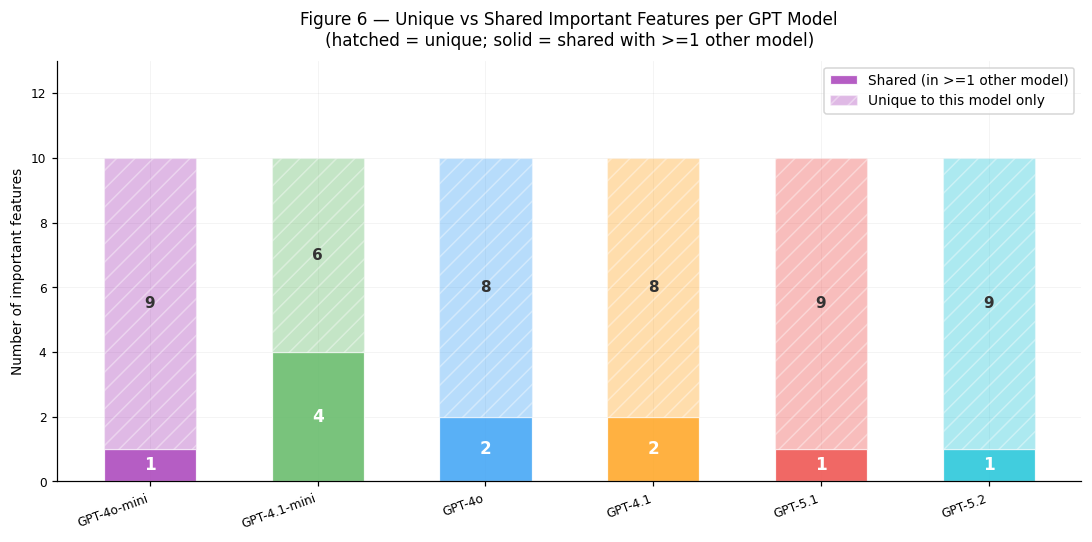

In [15]:
stacked_shared, stacked_unique = [], []
for mid in MODEL_IDS:
    imp = important_sets.get(mid, set())
    n_u = sum(1 for f in imp
              if all(f not in important_sets.get(m2, set()) for m2 in MODEL_IDS if m2 != mid))
    stacked_unique.append(n_u)
    stacked_shared.append(len(imp) - n_u)

x      = np.arange(len(MODEL_IDS))
width  = 0.55
colors = [MODEL_INFO[m]['color'] for m in MODEL_IDS]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x, stacked_shared, width, color=colors, alpha=0.88, edgecolor='white', linewidth=0.8,
       label='Shared (in >=1 other model)')
ax.bar(x, stacked_unique, width, bottom=stacked_shared, color=colors, alpha=0.38,
       hatch='//', edgecolor='white', linewidth=0.8, label='Unique to this model only')

for i, (s, u) in enumerate(zip(stacked_shared, stacked_unique)):
    if s > 0:
        ax.text(x[i], s / 2,       str(s), ha='center', va='center', fontsize=11, fontweight='bold', color='white')
    if u > 0:
        ax.text(x[i], s + u / 2,   str(u), ha='center', va='center', fontsize=10, fontweight='bold', color='#333')

ax.set_xticks(x); ax.set_xticklabels(LABELS, rotation=20, ha='right')
ax.set_ylabel('Number of important features')
ax.set_title(
    'Figure 6 — Unique vs Shared Important Features per GPT Model\n'
    '(hatched = unique; solid = shared with >=1 other model)',
    fontsize=11, pad=10)
ax.set_ylim(0, max(s + u for s, u in zip(stacked_shared, stacked_unique)) * 1.3)
ax.legend(fontsize=9, loc='upper right'); ax.set_axisbelow(True)
plt.tight_layout()
save_fig(fig, 'fig6_unique_vs_shared_per_model')
plt.show()